<a href="https://colab.research.google.com/github/InanyaMadan/counterfeit-siamese-verification/blob/main/Counterfeit_Siamese_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Few-Shot Counterfeit Currency Verification with a Siamese CNN
**BCSE332L Deep Learning, Team 9** (standalone Colab notebook, no GitHub needed)

**What this notebook does**
1. Downloads real **genuine Indian banknote photos** from Kaggle.
2. Synthesises **counterfeits** from them with 9 local print-failure types, each with a ground-truth defect mask.
3. Trains a **Siamese CNN** (ImageNet ResNet-18, batch-hard triplet loss) that measures how far a note is from genuine notes of the same denomination.
4. Evaluates with a **leave-one-type-out** protocol: one counterfeit type is never seen in training.
5. Compares against **baselines**: a fine-tuned supervised CNN, SVM / RF / LogReg / MLP / XGBoost on embeddings, and **PatchCore** anomaly detection.
6. **Few-shot** analysis (how many genuine references are needed) and defect **localisation** (Grad-CAM vs PatchCore maps) scored against the true defect masks.
7. **UCI Banknote Authentication** tabular benchmark.

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
Total time is roughly 35–55 minutes on a T4 (about 10 of them for note detection).

**Honesty note for the report:** the genuine notes are real photos, but the counterfeits are synthetic.
The optional section 15 tests on real counterfeit photos if you download a real-vs-fake dataset.

## 1. Setup

In [ ]:
!pip install -q kagglehub ucimlrepo xgboost

import os, re, json, math, time, random, hashlib, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print('PyTorch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE (set Runtime -> T4 GPU)')

PyTorch 2.11.0+cu130 | GPU: Tesla T4


## 2. Configuration
Everything you might want to change is here.

In [ ]:
CFG = dict(
    # data
    KAGGLE_GENUINE = 'vishalmane109/indian-currency-note-images-dataset-2020',  # genuine note photos
    KAGGLE_REAL_FAKE = '',      # optional, e.g. 'preetrank/indian-currency-real-vs-fake-notes-dataset' (section 12)
    MAX_PER_DENOM = 200,        # genuine notes kept per denomination (after cropping)
    CROP_NOTES = True,          # detect the note in each photo and crop to it (OWLv2)
    DET_MIN_SCORE = 0.2,        # detector confidence needed to keep a photo
    MIN_PER_DENOM = 20,         # skip denominations with fewer photos
    IMG_H = 192, IMG_W = 384,   # notes are ~2:1
    SPLIT = (0.6, 0.2, 0.2),    # train / val / test, split by physical note
    HOLDOUT = 'misregistration',# counterfeit type NEVER seen in training
    # model
    BACKBONE = 'resnet18',      # resnet18 | efficientnet_b0
    POOL = 'topk',              # topk (keeps sparse defect signal) | avg
    EMB_DIM = 128,
    LOSS = 'triplet',           # triplet (batch-hard) | contrastive
    MARGIN = 0.3,
    # training
    EPOCHS = 20, BATCH = 32, LR = 3e-4, PATIENCE = 5,
    STEPS_PER_EPOCH = 0,        # 0 = one pass over the training notes x 4
    CNN_BASELINE_EPOCHS = 10,
    SEED = 42,
    OUT = '/content/results',
)
os.makedirs(CFG['OUT'], exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

## 3. Download the genuine note photos (Kaggle)
Public datasets usually download without a login. If it asks for credentials:
kaggle.com → Settings → API → *Create New Token*, then add `KAGGLE_USERNAME` and `KAGGLE_KEY`
in Colab's 🔑 **Secrets** panel (left sidebar) and re-run this cell.

In [ ]:
import kagglehub

def kaggle_download(slug):
    try:
        return kagglehub.dataset_download(slug)
    except Exception as e:
        print('Anonymous download failed (', type(e).__name__, '), trying Colab secrets...')
        from google.colab import userdata
        os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        return kagglehub.dataset_download(slug)

GENUINE_SRC = kaggle_download(CFG['KAGGLE_GENUINE'])
print('Downloaded to', GENUINE_SRC)
for dp, dns, fns in list(os.walk(GENUINE_SRC))[:12]:
    print(dp.replace(GENUINE_SRC, '.'), '|', len(fns), 'files')

100%|██████████| 2.31G/2.31G [00:25<00:00, 96.9MB/s]

Extracting files...


Downloaded to /root/.cache/kagglehub/datasets/vishalmane109/indian-currency-note-images-dataset-2020/versions/1
. | 0 files
./Indian currency dataset v1 | 0 files
./Indian currency dataset v1/training | 0 files
./Indian currency dataset v1/training/10 | 448 files
./Indian currency dataset v1/training/500 | 437 files
./Indian currency dataset v1/training/100 | 450 files
./Indian currency dataset v1/training/Background | 393 files
./Indian currency dataset v1/training/20 | 450 files
./Indian currency dataset v1/training/200 | 500 files
./Indian currency dataset v1/training/2000 | 438 files
./Indian currency dataset v1/training/50 | 450 files
./Indian currency dataset v1/validation | 0 files


## 4. Find the notes and their denominations
The layout is detected automatically: the denomination comes from folder names
(`500`, `2000_new`, `5Hundrednote`, `Twenty`...), and folders named fake/counterfeit are kept out of training.

**Note detection and cropping.** Many dataset images are hand-held photos (fingers, floor, table) or web graphics,
where the note fills only part of the frame. A pretrained zero-shot object detector (**OWLv2**, Minderer et al., 2023)
finds the banknote in each image; the image is cropped to it, and images with no confidently detected note are
discarded. Without this, synthetic defects would often land on the background instead of the note.

Near-duplicate photos (augmented copies, the same note shot twice) are grouped with a perceptual hash
so they can never land on both sides of the train/test split.

4002 images found, 514 without a denomination skipped


config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

...

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  Rs10 genuine : kept 200 of 203 images (3 with no note detected)  [364s]
  Rs20 genuine : kept 200 of 208 images (8 with no note detected)  [324s]
  Rs50 genuine : kept 200 of 202 images (2 with no note detected)  [300s]
  Rs100 genuine : kept 200 of 212 images (12 with no note detected)  [306s]
  Rs200 genuine : kept 200 of 212 images (12 with no note detected)  [360s]
  Rs500 genuine : kept 200 of 209 images (9 with no note detected)  [310s]
  Rs2000 genuine : kept 200 of 212 images (12 with no note detected)  [316s]

Genuine notes per denomination:
  Rs10     200 photos,  195 distinct notes after de-duplication
  Rs20     200 photos,  193 distinct notes after de-duplication
  Rs50     200 photos,  194 distinct notes after de-duplication
  Rs100    200 photos,  181 distinct notes after de-duplication
  Rs200    200 photos,  163 distinct notes after de-duplication
  Rs500    200 photos,  182 distinct notes after de-duplication
  Rs2000   200 photos,  188 distinct notes after de-dupli

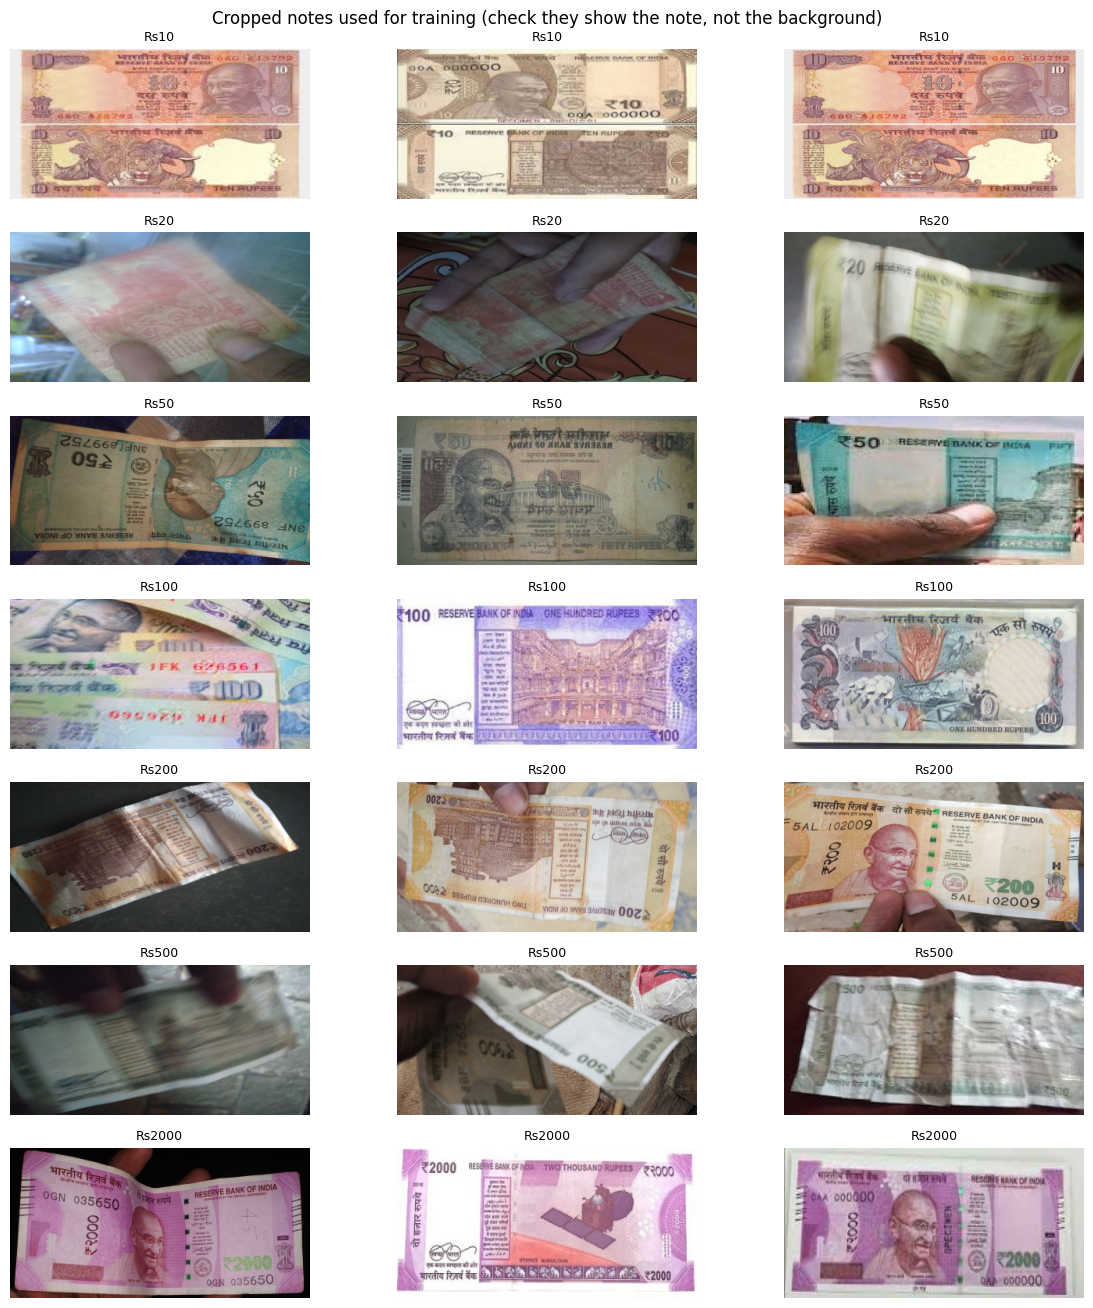

In [ ]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
WORDS = {'ten': 10, 'twenty': 20, 'fifty': 50}

def parse_denomination(path, root):
    parts = os.path.relpath(path, root).lower().split(os.sep)[:-1]
    for part in reversed(parts):
        if 'background' in part or 'other' == part:
            return None
        m = re.search(r'(\d+)\s*(hundred|thousand)', part)
        if m:
            return int(m.group(1)) * (100 if m.group(2) == 'hundred' else 1000)
        if 'thousand' in part: return 1000
        if 'hundred' in part:  return 100
        nums = [int(n) for n in re.findall(r'\d+', part)]
        nums = [n for n in nums if n in (10, 20, 50, 100, 200, 500, 2000)]
        if nums:
            return nums[0]
        for w, v in WORDS.items():
            if w in part:
                return v
    return None

def parse_label(path, root):
    rel = os.path.relpath(path, root).lower()
    if any(k in rel for k in ('fake', 'counterfeit', 'forg')):
        return 'fake'
    return 'genuine'

def dhash(img_bgr, size=8):
    g = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (size + 1, size))
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel())

def scan_notes(root, max_per=0, min_per=1, seed=0):
    files = sorted(os.path.join(dp, f) for dp, _, fns in os.walk(root)
                   for f in fns if f.lower().endswith(IMG_EXT))
    by = {}
    skipped = 0
    for f in files:
        d = parse_denomination(f, root)
        if d is None:
            skipped += 1; continue
        by.setdefault((d, parse_label(f, root)), []).append(f)
    rng = np.random.default_rng(seed)
    out = {}
    for (d, lab), fs in sorted(by.items()):
        rng.shuffle(fs)
        if lab == 'genuine' and len(fs) < min_per:
            print(f'  skip Rs{d}: only {len(fs)} photos'); continue
        out[(d, lab)] = fs[:max_per] if max_per else fs
    print(f'{len(files)} images found, {skipped} without a denomination skipped')
    return out

DETECTOR = None
NOTE_LABELS = ['a banknote', 'a currency note', 'paper money']

def detect_note(img_bgr, min_score):
    """Return (crop, score) for the banknote in the image, or (None, score) if none is found."""
    global DETECTOR
    if DETECTOR is None:
        from transformers import pipeline
        DETECTOR = pipeline('zero-shot-object-detection', model='google/owlv2-base-patch16-ensemble',
                            device=0 if torch.cuda.is_available() else -1)
    from PIL import Image
    h, w = img_bgr.shape[:2]; s = min(1.0, 1024 / max(h, w))
    small = cv2.resize(img_bgr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA) if s < 1 else img_bgr
    side = max(small.shape[:2])                       # pad to a square ourselves: box coordinates stay exact
    sq = np.full((side, side, 3), 127, np.uint8); sq[:small.shape[0], :small.shape[1]] = small
    preds = [p for p in DETECTOR(Image.fromarray(cv2.cvtColor(sq, cv2.COLOR_BGR2RGB)), candidate_labels=NOTE_LABELS)
             if p['score'] >= min_score]
    if not preds:
        return None, 0.0
    top = max(p['score'] for p in preds)
    # among confident boxes prefer the largest, so a whole note wins over a part of it
    b = max([p for p in preds if p['score'] >= 0.6 * top],
            key=lambda p: (p['box']['xmax'] - p['box']['xmin']) * (p['box']['ymax'] - p['box']['ymin']))
    x0, y0, x1, y1 = [b['box'][k] / s for k in ('xmin', 'ymin', 'xmax', 'ymax')]
    mx, my = 0.03 * (x1 - x0), 0.03 * (y1 - y0)
    x0, y0 = max(0, int(x0 - mx)), max(0, int(y0 - my)); x1, y1 = min(w, int(x1 + mx)), min(h, int(y1 + my))
    if x1 - x0 < 64 or y1 - y0 < 32:
        return None, float(b['score'])
    return img_bgr[y0:y1, x0:x1], float(b['score'])

def load_note(path, H, W, crop=False, min_score=0.2):
    raw = img = cv2.imread(path)
    if img is None: return None
    if crop:
        img, _ = detect_note(img, min_score)
        if img is None: return None
    if img.shape[0] > img.shape[1]:
        img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    # the duplicate hash uses the UNCROPPED photo: crops of different notes of one design look alike
    return raw, cv2.cvtColor(cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

def group_duplicates(hashes, max_bits=4):
    """Union-find over near-identical dHashes -> group id per image."""
    n = len(hashes); parent = list(range(n))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    H = np.unpackbits(np.stack(hashes), axis=1).astype(np.int16) if n else np.zeros((0, 64))
    for i in range(n):
        d = np.abs(H[i + 1:] - H[i]).sum(1)
        for j in np.where(d <= max_bits)[0] + i + 1:
            parent[find(j)] = find(i)
    gid = [find(i) for i in range(n)]
    # safety: a 'duplicate' group bigger than 5% of the photos is not a duplicate, split it back up
    sizes = {g: gid.count(g) for g in set(gid)}
    cap = max(3, int(0.05 * n))
    return [g if sizes[g] <= cap else f'{g}-{i}' for i, g in enumerate(gid)]

def build_note_table(groups, H, W, max_keep=0, crop=False, min_score=0.2):
    notes = []            # dicts: img (uint8 RGB HxW), denom, label, group
    for (d, lab), fs in groups.items():
        imgs, hs, tried, t0 = [], [], 0, time.time()
        for f in fs:
            if max_keep and len(imgs) >= max_keep: break
            tried += 1
            r = load_note(f, H, W, crop, min_score)
            if r is None: continue
            hs.append(dhash(r[0])); imgs.append(r[1])
        if crop:
            print(f'  Rs{d} {lab:8}: kept {len(imgs)} of {tried} images ({tried - len(imgs)} with no note detected)  [{time.time() - t0:.0f}s]')
        gid = group_duplicates(hs)
        for im, g in zip(imgs, gid):
            notes.append(dict(img=im, denom=d, label=lab, group=f'{d}-{lab}-{g}'))
    return notes

groups = scan_notes(GENUINE_SRC, 0, CFG['MIN_PER_DENOM'], CFG['SEED'])
NOTES = [n for n in build_note_table(groups, CFG['IMG_H'], CFG['IMG_W'], CFG['MAX_PER_DENOM'],
                                     CFG['CROP_NOTES'], CFG['DET_MIN_SCORE']) if n['label'] == 'genuine']
DENOMS = sorted({n['denom'] for n in NOTES})
print('\nGenuine notes per denomination:')
for d in DENOMS:
    ns = [n for n in NOTES if n['denom'] == d]
    print(f'  Rs{d:<5} {len(ns):4d} photos, {len({n["group"] for n in ns}):4d} distinct notes after de-duplication')
assert len(DENOMS) >= 1 and len(NOTES) >= 30, 'Too few notes found: check the dataset layout printed in section 3'

# visual check: 3 random cropped notes per denomination
_r = np.random.default_rng(CFG['SEED'])
fig, ax = plt.subplots(len(DENOMS), 3, figsize=(12, 1.9 * len(DENOMS)))
for row, d in zip(np.atleast_2d(ax), DENOMS):
    ids = [i for i, n in enumerate(NOTES) if n['denom'] == d]
    for a, i in zip(row, _r.choice(ids, min(3, len(ids)), replace=False)):
        a.imshow(NOTES[i]['img']); a.set_title(f'Rs{d}', fontsize=9); a.axis('off')
plt.suptitle('Cropped notes used for training (check they show the note, not the background)'); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/cropped_notes.png", dpi=100); plt.show()

## 5. Synthetic counterfeit generator
Each counterfeit type damages a **local region** (5–25% of the note), as real forgeries differ from genuine
notes in small areas. Every fake comes with a ground-truth mask, used later to score localisation.
Capture nuisances (lighting, slight tilt, JPEG) are applied **identically** to genuine and fake images,
so the model cannot cheat by spotting "was this image processed".
`missing_ink` and `misregistration` follow the defect types in the Banca d'Italia (2026) base paper.

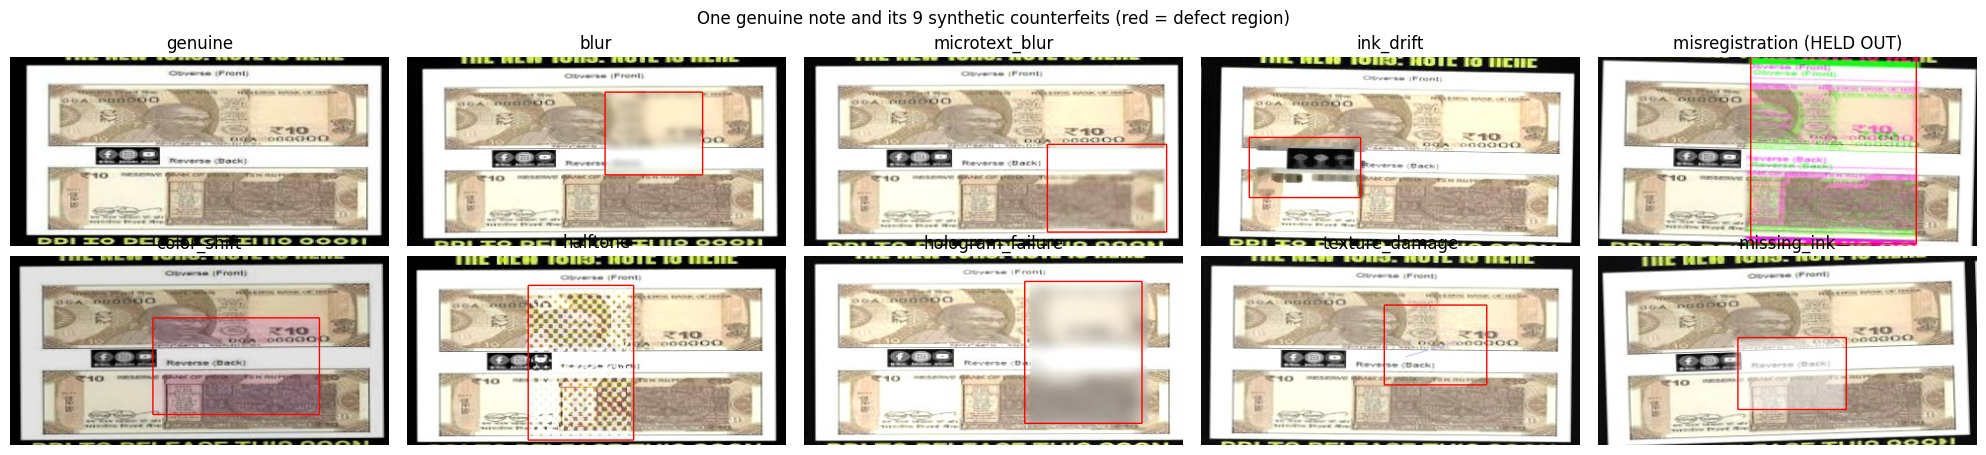

In [ ]:
def _region(rng, H, W, lo=0.05, hi=0.25):
    area = rng.uniform(lo, hi) * H * W
    ar = rng.uniform(0.5, 2.0)
    h = int(min(H - 2, max(8, math.sqrt(area / ar)))); w = int(min(W - 2, max(8, area / max(h, 1))))
    y = int(rng.integers(0, H - h)); x = int(rng.integers(0, W - w))
    m = np.zeros((H, W), np.float32); m[y:y + h, x:x + w] = 1
    return m, (y, x, h, w)

def _blend(img, alt, m):
    m3 = cv2.GaussianBlur(m, (0, 0), 1.5)[..., None]    # soft edge, no tell-tale rectangle
    return img * (1 - m3) + alt * m3

def d_blur(img, rng, m):
    return _blend(img, cv2.GaussianBlur(img, (0, 0), rng.uniform(1.8, 3.5)), m)

def d_microtext_blur(img, rng, m):
    H, W = img.shape[:2]; f = rng.uniform(0.3, 0.5)
    small = cv2.resize(img, (int(W * f), int(H * f)), interpolation=cv2.INTER_AREA)
    return _blend(img, cv2.resize(small, (W, H), interpolation=cv2.INTER_LINEAR), m)

def d_ink_drift(img, rng, m):
    k = int(rng.integers(1, 3)) * 2 + 1                  # ink spreads: dark strokes thicken
    return _blend(img, cv2.erode(img, np.ones((k, k), np.uint8)), m)

def d_misregistration(img, rng, m):
    alt = img.copy(); c = int(rng.integers(0, 3))        # one ink plate offset
    dx, dy = [int(v) * int(rng.choice([-1, 1])) for v in rng.integers(3, 7, 2)]
    alt[..., c] = np.roll(np.roll(img[..., c], dy, 0), dx, 1)
    return _blend(img, alt, m)

def d_color_shift(img, rng, m):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)            # float RGB in [0,1] -> H in [0,360)
    hsv[..., 0] = (hsv[..., 0] + rng.uniform(25, 60) * rng.choice([-1, 1])) % 360
    hsv[..., 1] = np.clip(hsv[..., 1] * rng.uniform(0.7, 1.3), 0, 1)
    return _blend(img, cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB), m)

def d_halftone(img, rng, m):
    H, W = img.shape[:2]; p = int(rng.integers(3, 6))      # cheap-printer dot screen
    yy, xx = np.mgrid[0:H, 0:W]
    screen = (np.sin(xx * np.pi / p) * np.sin(yy * np.pi / p) + 1) / 2
    alt = np.where(img > screen[..., None] * 0.9 + 0.05, 1.0, img * 0.55)
    return _blend(img, (alt * 0.6 + img * 0.4).astype(np.float32), m)

def d_hologram_failure(img, rng, m):
    flat = cv2.GaussianBlur(img, (0, 0), 6)                # 'dead' hologram: flat, desaturated patch
    g = flat.mean(2, keepdims=True)
    return _blend(img, (0.5 * flat + 0.5 * g) * rng.uniform(0.9, 1.1), m)

def d_texture_damage(img, rng, m):
    alt = img.copy(); H, W = img.shape[:2]
    for _ in range(int(rng.integers(6, 14))):            # scratches + paper grain
        p1 = (int(rng.integers(0, W)), int(rng.integers(0, H)))
        p2 = (p1[0] + int(rng.integers(-60, 60)), p1[1] + int(rng.integers(-30, 30)))
        cv2.line(alt, p1, p2, tuple(float(v) for v in rng.uniform(0.6, 1.0, 3)), 1)
    alt = alt + rng.normal(0, 0.04, img.shape).astype(np.float32)
    return _blend(img, alt, m)

def d_missing_ink(img, rng, m):
    a = rng.uniform(0.35, 0.7)                             # ink did not transfer: fades to paper
    return _blend(img, img + (1 - img) * a, m)

DEFECTS = {f.__name__[2:]: f for f in [d_blur, d_microtext_blur, d_ink_drift, d_misregistration,
           d_color_shift, d_halftone, d_hologram_failure, d_texture_damage, d_missing_ink]}
TYPES = list(DEFECTS)
assert CFG['HOLDOUT'] in TYPES, f"HOLDOUT must be one of {TYPES}"
SEEN = [t for t in TYPES if t != CFG['HOLDOUT']]

def capture(img, rng):
    """Same camera/scanner nuisance for genuine and fake."""
    H, W = img.shape[:2]
    a = rng.uniform(-2, 2); s = rng.uniform(0.97, 1.03)
    M = cv2.getRotationMatrix2D((W / 2, H / 2), a, s); M[:, 2] += rng.uniform(-4, 4, 2)
    out = cv2.warpAffine(img, M, (W, H), borderMode=cv2.BORDER_REFLECT)
    out = np.clip(out * rng.uniform(0.85, 1.15) + rng.uniform(-0.05, 0.05), 0, 1) ** rng.uniform(0.9, 1.1)
    q = int(rng.integers(75, 96))
    enc = cv2.imencode('.jpg', (out * 255).astype(np.uint8), [cv2.IMWRITE_JPEG_QUALITY, q])[1]
    return cv2.imdecode(enc, cv2.IMREAD_UNCHANGED).astype(np.float32) / 255

def make_sample(note_img, kind, rng):
    """kind = 'genuine' or a defect type. Returns uint8 RGB image and defect mask (H,W)."""
    img = note_img.astype(np.float32) / 255
    H, W = img.shape[:2]
    mask = np.zeros((H, W), np.float32)
    if kind != 'genuine':
        mask, _ = _region(rng, H, W, *( (0.25, 0.6) if kind == 'misregistration' else (0.05, 0.25)))
        img = np.clip(DEFECTS[kind](img, rng, mask), 0, 1).astype(np.float32)
    return (capture(img, rng) * 255).astype(np.uint8), mask

def det_rng(*key):
    """Deterministic RNG per (note, kind, shot) so eval images are identical every time."""
    h = hashlib.md5(('|'.join(map(str, key)) + str(CFG['SEED'])).encode()).hexdigest()
    return np.random.default_rng(int(h[:16], 16))

ex = NOTES[0]['img']
fig, ax = plt.subplots(2, 5, figsize=(20, 4.6))
for a, k in zip(ax.ravel(), ['genuine'] + TYPES):
    im, mk = make_sample(ex, k, det_rng('demo', k))
    a.imshow(im)
    if mk.any(): a.contour(mk, levels=[0.5], colors='r', linewidths=1)
    a.set_title(k + (' (HELD OUT)' if k == CFG['HOLDOUT'] else '')); a.axis('off')
plt.suptitle('One genuine note and its 9 synthetic counterfeits (red = defect region)'); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/counterfeit_types.png", dpi=120); plt.show()

## 6. Split by physical note
Duplicate groups stay together, and each denomination is split separately, so every split has every denomination.
The test set has each test note as genuine (2 captures) plus one counterfeit of **every** type.
Validation uses **seen** types only, so the held-out type never influences model selection.

In [ ]:
def split_notes(notes, frac, seed):
    rng = np.random.default_rng(seed); idx = {'train': [], 'val': [], 'test': []}
    for d in DENOMS:
        gs = sorted({n['group'] for n in notes if n['denom'] == d}); rng.shuffle(gs)
        a, b = int(frac[0] * len(gs)), int((frac[0] + frac[1]) * len(gs))
        part = {g: ('train' if i < a else 'val' if i < b else 'test') for i, g in enumerate(gs)}
        for i, n in enumerate(notes):
            if n['denom'] == d: idx[part[n['group']]].append(i)
    return idx

SPLIT = split_notes(NOTES, CFG['SPLIT'], CFG['SEED'])
assert not ({NOTES[i]['group'] for i in SPLIT['train']} & {NOTES[i]['group'] for i in SPLIT['test']})

def eval_items(idx, kinds, shots=2):
    """(note_index, kind, shot) tuples; label 0 genuine / 1 fake."""
    items = []
    for i in idx:
        items += [(i, 'genuine', s) for s in range(shots)]
        items += [(i, k, 0) for k in kinds]
    return items

VAL_ITEMS = eval_items(SPLIT['val'], SEEN)
TEST_ITEMS = eval_items(SPLIT['test'], TYPES)
print({k: len(v) for k, v in SPLIT.items()}, 'notes |', len(VAL_ITEMS), 'val images |', len(TEST_ITEMS), 'test images')
print('Held-out counterfeit type:', CFG['HOLDOUT'])

{'train': 827, 'val': 282, 'test': 291} notes | 2820 val images | 3201 test images
Held-out counterfeit type: misregistration


## 7. Siamese network
Shared-weight ImageNet backbone → top-k spatial pooling → 128-d L2-normalised embedding.
**Top-k pooling** averages only the strongest 10% of locations per channel; plain average pooling
would dilute a defect that covers a few percent of the note (set `POOL='avg'` to compare).

**Batch-hard triplet loss.** Each training note gives an anchor and a positive (two genuine captures)
and a negative (a counterfeit of a seen type). For each anchor the loss takes the *farthest* genuine of the same
denomination and the *closest* counterfeit of the same denomination in the batch. Counterfeits are only pushed away
from genuine notes, never pulled together, so an unseen forgery just has to look "far from genuine".

In [ ]:
import torch.nn as nn, torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def to_tensor(img_u8):
    return (torch.from_numpy(img_u8).permute(2, 0, 1).float() / 255 - MEAN) / STD

class TopKPool(nn.Module):
    def __init__(self, frac=0.1): super().__init__(); self.frac = frac
    def forward(self, x):
        f = x.flatten(2); k = max(1, int(f.shape[-1] * self.frac))
        return f.topk(k, dim=-1).values.mean(-1)

class SiameseNet(nn.Module):
    def __init__(self, backbone='resnet18', pool='topk', dim=128):
        super().__init__()
        if backbone == 'resnet18':
            m = torchvision.models.resnet18(weights='IMAGENET1K_V1')
            self.body = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4); c = 512
        elif backbone == 'efficientnet_b0':
            m = torchvision.models.efficientnet_b0(weights='IMAGENET1K_V1'); self.body = m.features; c = 1280
        else:
            raise ValueError(backbone)
        self.pool = TopKPool() if pool == 'topk' else nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Linear(c, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Linear(256, dim))
    def embed_from_fmap(self, fmap):
        return F.normalize(self.head(self.pool(fmap).flatten(1)), dim=1)
    def forward(self, x):
        return self.embed_from_fmap(self.body(x))

class TripletTrainSet(Dataset):
    """Random (genuine, genuine, fake-of-a-seen-type) triplets, generated on the fly."""
    def __init__(self, idx, kinds, length):
        self.idx, self.kinds, self.length = idx, kinds, length
        self.by_denom = {d: [i for i in idx if NOTES[i]['denom'] == d] for d in DENOMS}
    def __len__(self): return self.length
    def __getitem__(self, _):
        rng = np.random.default_rng()
        i = int(rng.choice(self.idx)); d = NOTES[i]['denom']
        a, _ = make_sample(NOTES[i]['img'], 'genuine', rng)
        j = i if rng.random() < 0.5 else int(rng.choice(self.by_denom[d]))   # same note or another note
        p, _ = make_sample(NOTES[j]['img'], 'genuine', rng)
        n, _ = make_sample(NOTES[i]['img'], str(rng.choice(self.kinds)), rng)  # same photo, one defect
        return to_tensor(a), to_tensor(p), to_tensor(n), d

class EvalSet(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, k):
        i, kind, s = self.items[k]
        img, _ = make_sample(NOTES[i]['img'], kind, det_rng(i, kind, s))
        return to_tensor(img), int(kind != 'genuine'), NOTES[i]['denom']

def worker_init(w): np.random.seed((torch.initial_seed() + w) % 2**32)

def batch_hard_loss(ea, ep, en, d, margin):
    G = torch.cat([ea, ep]); gd = torch.cat([d, d]); B = ea.shape[0]
    dg = torch.cdist(ea, G)                                  # anchor vs all genuine
    same = (d[:, None] == gd[None]); same[torch.arange(B), torch.arange(B)] = False
    hard_pos = (dg * same).max(1).values
    dn = torch.cdist(ea, en)
    dn = dn.masked_fill(d[:, None] != d[None], 1e4)           # only fakes of the same denomination
    hard_neg = dn.min(1).values
    return F.relu(hard_pos - hard_neg + margin).mean()

def contrastive_loss(ea, ep, en, d, margin):
    dp = (ea - ep).pow(2).sum(1); dn = (ea - en).norm(dim=1)
    return (dp + F.relu(margin * 2 - dn).pow(2)).mean()

## 8. Scoring and metrics
A note's **counterfeit score** is its mean distance to the 3 nearest genuine **reference** embeddings
of the same denomination (the reference bank = genuine training notes). No classifier is involved.

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_fscore_support, confusion_matrix

@torch.no_grad()
def embed_items(model, items, bs=64):
    model.eval(); E, Y, D = [], [], []
    for x, y, d in DataLoader(EvalSet(items), batch_size=bs, num_workers=2, worker_init_fn=worker_init):
        with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
            E.append(model(x.to(DEVICE)).float().cpu())
        Y.append(y); D.append(d)
    return torch.cat(E).numpy(), torch.cat(Y).numpy(), torch.cat(D).numpy()

def build_bank(model, idx, k_per_denom=0, rng=None):
    sel = []
    for d in DENOMS:
        ids = [i for i in idx if NOTES[i]['denom'] == d]
        if k_per_denom and rng is not None: ids = list(rng.choice(ids, min(k_per_denom, len(ids)), replace=False))
        sel += ids
    E, _, D = embed_items(model, [(i, 'genuine', 0) for i in sel])
    return E, D

def score(E, D, bank_E, bank_D, k=3):
    s = np.empty(len(E))
    for d in np.unique(D):
        q = D == d; ref = bank_E[bank_D == d]
        if len(ref) == 0: ref = bank_E                       # unseen denomination: use whole bank
        dist = np.sqrt(np.maximum(((E[q, None] - ref[None]) ** 2).sum(-1), 0))
        s[q] = np.sort(dist, 1)[:, :min(k, ref.shape[0])].mean(1)
    return s

def eer_threshold(y, s):
    fpr, tpr, th = roc_curve(y, s); fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr)); return float((fpr[i] + fnr[i]) / 2), float(th[i])

def tpr_at_fpr(y, s, target=0.01):
    fpr, tpr, _ = roc_curve(y, s); return float(np.interp(target, fpr, tpr))

def metrics(y, s, thr):
    p = (s >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(auroc=float(roc_auc_score(y, s)), eer=eer_threshold(y, s)[0], tpr_at_1pct_fpr=tpr_at_fpr(y, s),
                precision=float(pr), recall=float(rc), f1=float(f1), accuracy=float((p == y).mean()),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

KINDS_TEST = np.array([k for _, k, _ in TEST_ITEMS])
def masks_for(kinds_arr, types):
    return np.isin(kinds_arr, ['genuine'] + list(types))

## 9. Train the Siamese network
Mixed precision, AdamW, cosine schedule, early stopping on validation AUROC (seen types only).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


[siamese] epoch  1  loss 0.4841  val AUROC 0.7552  (81s)
[siamese] epoch  2  loss 0.3538  val AUROC 0.8402  (80s)
[siamese] epoch  3  loss 0.3243  val AUROC 0.8592  (78s)
[siamese] epoch  4  loss 0.3087  val AUROC 0.8685  (79s)
[siamese] epoch  5  loss 0.2917  val AUROC 0.8668  (79s)
[siamese] epoch  6  loss 0.2896  val AUROC 0.8854  (83s)
[siamese] epoch  7  loss 0.2798  val AUROC 0.8950  (80s)
[siamese] epoch  8  loss 0.2718  val AUROC 0.8969  (78s)
[siamese] epoch  9  loss 0.2780  val AUROC 0.9065  (80s)
[siamese] epoch 10  loss 0.2571  val AUROC 0.9173  (79s)
[siamese] epoch 11  loss 0.2407  val AUROC 0.9121  (78s)
[siamese] epoch 12  loss 0.2317  val AUROC 0.9162  (78s)
[siamese] epoch 13  loss 0.2320  val AUROC 0.9230  (78s)
[siamese] epoch 14  loss 0.2056  val AUROC 0.9327  (78s)
[siamese] epoch 15  loss 0.1975  val AUROC 0.9318  (78s)
[siamese] epoch 16  loss 0.1884  val AUROC 0.9290  (79s)
[siamese] epoch 17  loss 0.1742  val AUROC 0.9292  (79s)
[siamese] epoch 18  loss 0.1618

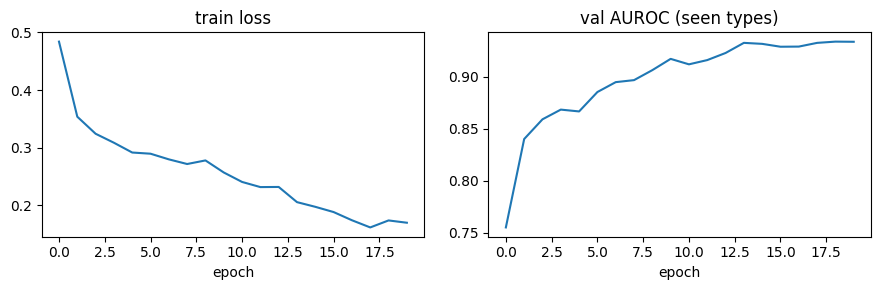

In [ ]:
def train_siamese(holdout=CFG['HOLDOUT'], epochs=CFG['EPOCHS'], tag='siamese', verbose=True):
    seen = [t for t in TYPES if t != holdout]
    model = SiameseNet(CFG['BACKBONE'], CFG['POOL'], CFG['EMB_DIM']).to(DEVICE)
    steps = CFG['STEPS_PER_EPOCH'] or max(20, 4 * len(SPLIT['train']) // CFG['BATCH'])
    dl = DataLoader(TripletTrainSet(SPLIT['train'], seen, steps * CFG['BATCH']), batch_size=CFG['BATCH'],
                    num_workers=2, worker_init_fn=worker_init, drop_last=True, persistent_workers=True)
    opt = torch.optim.AdamW([{'params': model.body.parameters(), 'lr': CFG['LR'] / 3},
                             {'params': model.head.parameters(), 'lr': CFG['LR']}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
    loss_fn = batch_hard_loss if CFG['LOSS'] == 'triplet' else contrastive_loss
    val_items = eval_items(SPLIT['val'], seen)
    best, bad, hist = -1, 0, []
    for ep in range(epochs):
        model.train(); t0 = time.time(); tot = 0
        for a, p, n, d in dl:
            a, p, n, d = a.to(DEVICE), p.to(DEVICE), n.to(DEVICE), d.to(DEVICE)
            with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
                e = model(torch.cat([a, p, n]))
            e = e.float(); B = a.shape[0]
            loss = loss_fn(e[:B], e[B:2 * B], e[2 * B:], d, CFG['MARGIN'])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()
        sched.step()
        bE, bD = build_bank(model, SPLIT['train'])
        vE, vY, vD = embed_items(model, val_items)
        auc = roc_auc_score(vY, score(vE, vD, bE, bD))
        hist.append(dict(epoch=ep + 1, loss=tot / len(dl), val_auroc=float(auc)))
        if verbose: print(f'[{tag}] epoch {ep + 1:2d}  loss {tot / len(dl):.4f}  val AUROC {auc:.4f}  ({time.time() - t0:.0f}s)')
        if auc > best:
            best, bad = auc, 0; torch.save(model.state_dict(), f"{CFG['OUT']}/{tag}_best.pt")
        else:
            bad += 1
            if bad >= CFG['PATIENCE']:
                if verbose: print('early stopping'); break
    model.load_state_dict(torch.load(f"{CFG['OUT']}/{tag}_best.pt", map_location=DEVICE))
    return model, hist

model, HIST = train_siamese()
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.plot([h['loss'] for h in HIST]); plt.title('train loss'); plt.xlabel('epoch')
plt.subplot(1, 2, 2); plt.plot([h['val_auroc'] for h in HIST]); plt.title('val AUROC (seen types)'); plt.xlabel('epoch')
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/training_curves.png", dpi=120); plt.show()

## 10. Evaluate: seen vs **unseen** counterfeit type
The decision threshold is fixed on the validation set (EER point, seen types only), then applied to the test set.

Held-out type: misregistration

             AUROC     EER  TPR@1%FPR   Prec  Recall     F1
seen         0.952   0.115      0.691  0.974   0.870  0.919
unseen       0.886   0.198      0.419  0.778   0.639  0.702

AUROC per counterfeit type:
  color_shift        0.797
  misregistration    0.886   <- never seen in training
  texture_damage     0.930
  ink_drift          0.954
  microtext_blur     0.968
  missing_ink        0.980
  blur               0.990
  halftone           0.996
  hologram_failure   0.998


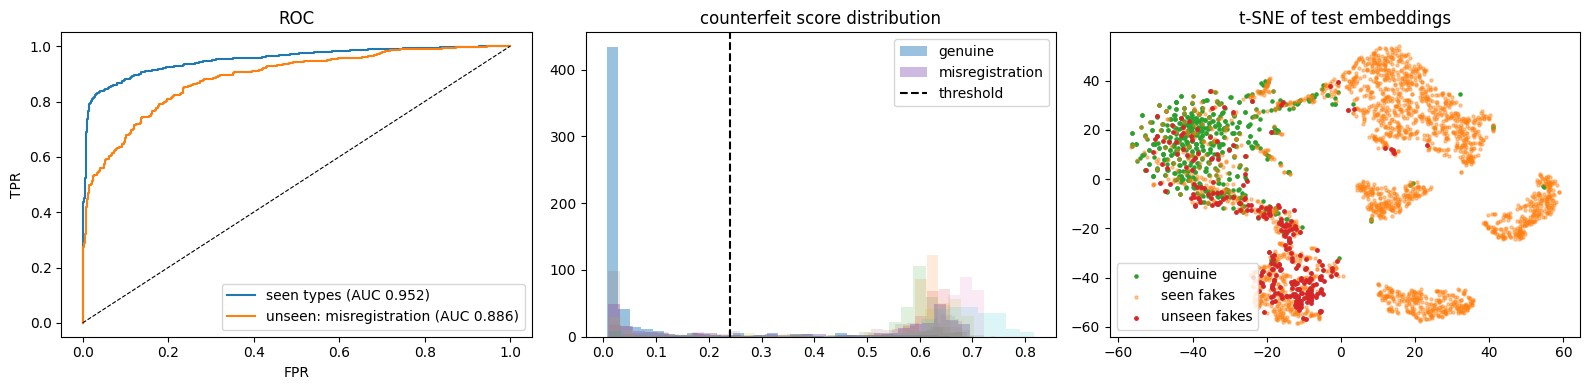

In [ ]:
def evaluate_siamese(model, holdout):
    seen = [t for t in TYPES if t != holdout]
    bE, bD = build_bank(model, SPLIT['train'])
    vE, vY, vD = embed_items(model, eval_items(SPLIT['val'], seen))
    _, thr = eer_threshold(vY, score(vE, vD, bE, bD))
    tE, tY, tD = embed_items(model, TEST_ITEMS)
    s = score(tE, tD, bE, bD)
    seen_m, held_m = masks_for(KINDS_TEST, seen), masks_for(KINDS_TEST, [holdout])
    res = dict(threshold=thr, seen=metrics(tY[seen_m], s[seen_m], thr), unseen=metrics(tY[held_m], s[held_m], thr),
               per_type_auroc={t: float(roc_auc_score(tY[masks_for(KINDS_TEST, [t])], s[masks_for(KINDS_TEST, [t])])) for t in TYPES})
    return res, (tE, tY, tD, s, bE, bD)

RES, (TE, TY, TD, TS, BE, BD) = evaluate_siamese(model, CFG['HOLDOUT'])
print(f"Held-out type: {CFG['HOLDOUT']}\n")
print(f"{'':10}{'AUROC':>8}{'EER':>8}{'TPR@1%FPR':>11}{'Prec':>7}{'Recall':>8}{'F1':>7}")
for k in ('seen', 'unseen'):
    m = RES[k]; print(f"{k:10}{m['auroc']:8.3f}{m['eer']:8.3f}{m['tpr_at_1pct_fpr']:11.3f}{m['precision']:7.3f}{m['recall']:8.3f}{m['f1']:7.3f}")
print('\nAUROC per counterfeit type:')
for t, v in sorted(RES['per_type_auroc'].items(), key=lambda kv: kv[1]):
    print(f"  {t:18} {v:.3f}{'   <- never seen in training' if t == CFG['HOLDOUT'] else ''}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for k, m in (('seen types', masks_for(KINDS_TEST, SEEN)), (f"unseen: {CFG['HOLDOUT']}", masks_for(KINDS_TEST, [CFG['HOLDOUT']]))):
    fpr, tpr, _ = roc_curve(TY[m], TS[m]); ax[0].plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(TY[m], TS[m]):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(); ax[0].set_title('ROC')
for k in ['genuine'] + TYPES:
    ax[1].hist(TS[KINDS_TEST == k], bins=30, alpha=.45 if k in ('genuine', CFG['HOLDOUT']) else .15, label=k if k in ('genuine', CFG['HOLDOUT']) else None)
ax[1].axvline(RES['threshold'], color='k', ls='--', label='threshold'); ax[1].legend(); ax[1].set_title('counterfeit score distribution')
from sklearn.manifold import TSNE
z = TSNE(2, random_state=0, perplexity=30).fit_transform(TE)
for k, c in (('genuine', 'tab:green'), ):
    ax[2].scatter(*z[KINDS_TEST == k].T, s=5, c=c, label=k)
ax[2].scatter(*z[np.isin(KINDS_TEST, SEEN)].T, s=5, c='tab:orange', alpha=.4, label='seen fakes')
ax[2].scatter(*z[KINDS_TEST == CFG['HOLDOUT']].T, s=6, c='tab:red', label='unseen fakes'); ax[2].legend(); ax[2].set_title('t-SNE of test embeddings')
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/evaluation.png", dpi=120); plt.show()

## 11. Baselines: does classification generalise to the unseen type?
**(a) Supervised CNN** (slide 4's first row): the same ImageNet ResNet-18 fine-tuned as a genuine-vs-fake classifier
on the same training notes and the same seen counterfeit types.
**(b) Classical classifiers on the Siamese embeddings**: SVM, Random Forest, Logistic Regression, MLP, XGBoost.

In [ ]:
class ClassifierTrainSet(Dataset):
    def __init__(self, idx, kinds, length): self.idx, self.kinds, self.length = idx, kinds, length
    def __len__(self): return self.length
    def __getitem__(self, _):
        rng = np.random.default_rng(); i = int(rng.choice(self.idx))
        kind = 'genuine' if rng.random() < 0.5 else str(rng.choice(self.kinds))
        img, _ = make_sample(NOTES[i]['img'], kind, rng)
        return to_tensor(img), float(kind != 'genuine')

def train_cnn_classifier(holdout, epochs=CFG['CNN_BASELINE_EPOCHS']):
    seen = [t for t in TYPES if t != holdout]
    m = torchvision.models.resnet18(weights='IMAGENET1K_V1'); m.fc = nn.Linear(512, 1); m = m.to(DEVICE)
    steps = CFG['STEPS_PER_EPOCH'] or max(20, 4 * len(SPLIT['train']) // CFG['BATCH'])
    dl = DataLoader(ClassifierTrainSet(SPLIT['train'], seen, steps * CFG['BATCH']), batch_size=CFG['BATCH'],
                    num_workers=2, worker_init_fn=worker_init, drop_last=True, persistent_workers=True)
    opt = torch.optim.AdamW(m.parameters(), lr=CFG['LR'] / 3, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
    for ep in range(epochs):
        m.train(); tot = 0
        for x, y in dl:
            with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
                loss = F.binary_cross_entropy_with_logits(m(x.to(DEVICE)).squeeze(1).float(), y.float().to(DEVICE))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        print(f'[cnn classifier] epoch {ep + 1:2d}  loss {tot / len(dl):.4f}')
    return m

@torch.no_grad()
def cnn_scores(m, items):
    m.eval(); out = []
    for x, _, _ in DataLoader(EvalSet(items), batch_size=64, num_workers=2, worker_init_fn=worker_init):
        with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
            out.append(torch.sigmoid(m(x.to(DEVICE)).float()).squeeze(1).cpu())
    return torch.cat(out).numpy()

cnn = train_cnn_classifier(CFG['HOLDOUT'])
cs = cnn_scores(cnn, TEST_ITEMS)
seen_m, held_m = masks_for(KINDS_TEST, SEEN), masks_for(KINDS_TEST, [CFG['HOLDOUT']])
BASE = {'Supervised CNN (ResNet-18 + BCE)': (roc_auc_score(TY[seen_m], cs[seen_m]), roc_auc_score(TY[held_m], cs[held_m]))}
del cnn; torch.cuda.empty_cache()

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

def classical_baselines(Xtr, ytr, Xte, seed=CFG['SEED']):
    clfs = {'SVM (RBF)': SVC(kernel='rbf', C=2.0, probability=True, random_state=seed),
            'Random Forest': RandomForestClassifier(300, random_state=seed, n_jobs=-1),
            'Logistic Regression': LogisticRegression(max_iter=3000),
            'MLP': MLPClassifier((256, 64), max_iter=600, random_state=seed),
            'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, eval_metric='logloss', random_state=seed)}
    return {k: make_pipeline(StandardScaler(), c).fit(Xtr, ytr).predict_proba(Xte)[:, 1] for k, c in clfs.items()}

trE, trY, _ = embed_items(model, eval_items(SPLIT['train'], SEEN, shots=1))
for name, p in classical_baselines(trE, trY, TE).items():
    BASE[f'{name} on embeddings'] = (roc_auc_score(TY[seen_m], p[seen_m]), roc_auc_score(TY[held_m], p[held_m]))
BASE['Siamese verifier (ours)'] = (RES['seen']['auroc'], RES['unseen']['auroc'])

print(f"{'method':42}{'AUROC seen':>12}{'AUROC unseen':>14}")
for k, (a, b) in BASE.items(): print(f'{k:42}{a:12.3f}{b:14.3f}')

[cnn classifier] epoch  1  loss 0.6121
[cnn classifier] epoch  2  loss 0.5084
[cnn classifier] epoch  3  loss 0.4293
[cnn classifier] epoch  4  loss 0.3954
[cnn classifier] epoch  5  loss 0.3478
[cnn classifier] epoch  6  loss 0.3221
[cnn classifier] epoch  7  loss 0.2836
[cnn classifier] epoch  8  loss 0.2860
[cnn classifier] epoch  9  loss 0.2567
[cnn classifier] epoch 10  loss 0.2445
method                                      AUROC seen  AUROC unseen
Supervised CNN (ResNet-18 + BCE)                 0.944         0.832
SVM (RBF) on embeddings                          0.860         0.824
Random Forest on embeddings                      0.935         0.870
Logistic Regression on embeddings                0.916         0.838
MLP on embeddings                                0.920         0.862
XGBoost on embeddings                            0.946         0.858
Siamese verifier (ours)                          0.952         0.886


## 11b. PatchCore baseline (anomaly detection, Roth et al., CVPR 2022)
The strongest anomaly-detection competitor from the literature review. It uses **no training and no counterfeits**:
1. Frozen ImageNet ResNet-18 features from layers 2 and 3, averaged over each 3×3 neighbourhood → one feature per patch.
2. A **memory bank** of patch features from genuine training notes, one bank per denomination, reduced with
   **greedy coreset sampling** (k-centre on a random projection) to 10% of patches, as in the paper.
3. A note's score is its **most anomalous patch**: the largest nearest-neighbour distance to the bank.
   The per-patch distances form a defect heatmap, compared with Grad-CAM in section 13.

The paper uses a WideResNet-50; ResNet-18 is used here to match the Siamese backbone and fit Colab memory.

Rs10: 140544 patches -> coreset 10000
Rs20: 134784 patches -> coreset 10000
Rs50: 139392 patches -> coreset 10000
Rs100: 132480 patches -> coreset 10000
Rs200: 131328 patches -> coreset 10000
Rs500: 139392 patches -> coreset 10000
Rs2000: 134784 patches -> coreset 10000
PatchCore done in 94s

method                                      AUROC seen  AUROC unseen
Supervised CNN (ResNet-18 + BCE)                 0.944         0.832
SVM (RBF) on embeddings                          0.860         0.824
Random Forest on embeddings                      0.935         0.870
Logistic Regression on embeddings                0.916         0.838
MLP on embeddings                                0.920         0.862
XGBoost on embeddings                            0.946         0.858
PatchCore (genuine only, no training)            0.525         0.548
Siamese verifier (ours)                          0.952         0.886

per-type AUROC        Siamese  PatchCore
blur                    0.990      0.527
mi

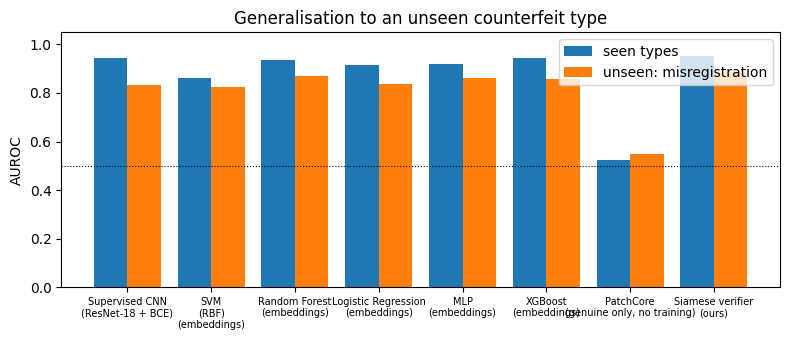

In [ ]:
class PatchFeatures(nn.Module):
    def __init__(self):
        super().__init__()
        m = torchvision.models.resnet18(weights='IMAGENET1K_V1')
        self.stem = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1); self.l2, self.l3 = m.layer2, m.layer3
        for p in self.parameters(): p.requires_grad = False
    @torch.no_grad()
    def forward(self, x):
        f2 = self.l2(self.stem(x)); f3 = self.l3(f2)
        f3 = F.interpolate(f3, size=f2.shape[-2:], mode='bilinear', align_corners=False)
        return F.avg_pool2d(torch.cat([f2, f3], 1), 3, 1, 1)          # (B, 384, H/8, W/8)

@torch.no_grad()
def patch_feature_batches(pf, items, bs=16):
    for x, y, d in DataLoader(EvalSet(items), batch_size=bs, num_workers=2, worker_init_fn=worker_init):
        yield pf(x.to(DEVICE)).float(), y, d

@torch.no_grad()
def greedy_coreset(X, frac=0.1, max_n=10000, seed=CFG['SEED']):
    n = min(max_n, max(1, int(len(X) * frac)))
    g = torch.Generator().manual_seed(seed)
    Z = X @ (torch.randn(X.shape[1], 128, generator=g) / math.sqrt(128)).to(X.device)
    idx = [int(torch.randint(len(X), (1,), generator=g))]
    mind = (Z - Z[idx[0]]).norm(dim=1)
    for _ in range(n - 1):
        i = int(mind.argmax()); idx.append(i)
        mind = torch.minimum(mind, (Z - Z[i]).norm(dim=1))
    return X[idx]

t0 = time.time()
PF = PatchFeatures().to(DEVICE).eval(); PC_BANK = {}
for d in DENOMS:
    items = [(i, 'genuine', 0) for i in SPLIT['train'] if NOTES[i]['denom'] == d]
    X = torch.cat([f.permute(0, 2, 3, 1).reshape(-1, f.shape[1]) for f, _, _ in patch_feature_batches(PF, items)])
    PC_BANK[d] = greedy_coreset(X)
    print(f'Rs{d}: {len(X)} patches -> coreset {len(PC_BANK[d])}')
    del X
ALL_BANK = torch.cat(list(PC_BANK.values()))

@torch.no_grad()
def patchcore_score(items):
    scores, maps = [], []
    for f, _, d in patch_feature_batches(PF, items):
        for b in range(f.shape[0]):
            bank = PC_BANK.get(int(d[b]), ALL_BANK)
            q = f[b].permute(1, 2, 0).reshape(-1, f.shape[1])
            s = torch.cdist(q, bank).min(1).values.reshape(f.shape[2], f.shape[3])
            scores.append(float(s.max())); maps.append(s.cpu().numpy())
    return np.array(scores), maps

def patchcore_heatmap(pmap, H, W):
    return cv2.GaussianBlur(cv2.resize(pmap, (W, H), interpolation=cv2.INTER_LINEAR), (0, 0), 4)

PC_S, PC_MAPS = patchcore_score(TEST_ITEMS)
BASE['PatchCore (genuine only, no training)'] = (roc_auc_score(TY[seen_m], PC_S[seen_m]), roc_auc_score(TY[held_m], PC_S[held_m]))
PC_PER_TYPE = {t: float(roc_auc_score(TY[masks_for(KINDS_TEST, [t])], PC_S[masks_for(KINDS_TEST, [t])])) for t in TYPES}
print(f'PatchCore done in {time.time() - t0:.0f}s\n')

order = ['Supervised CNN (ResNet-18 + BCE)'] + [k for k in BASE if k.endswith('on embeddings')] + \
        ['PatchCore (genuine only, no training)', 'Siamese verifier (ours)']
BASE = {k: BASE[k] for k in order}
print(f"{'method':42}{'AUROC seen':>12}{'AUROC unseen':>14}")
for k, (a, b) in BASE.items(): print(f'{k:42}{a:12.3f}{b:14.3f}')
print(f"\n{'per-type AUROC':20}{'Siamese':>9}{'PatchCore':>11}")
for t in TYPES: print(f"{t:20}{RES['per_type_auroc'][t]:9.3f}{PC_PER_TYPE[t]:11.3f}{'   <- unseen by Siamese' if t == CFG['HOLDOUT'] else ''}")
json.dump({k: {'seen': float(a), 'unseen': float(b)} for k, (a, b) in BASE.items()}, open(f"{CFG['OUT']}/baselines.json", 'w'), indent=2)

plt.figure(figsize=(8, 3.5)); names = list(BASE); xs = np.arange(len(names))
plt.bar(xs - 0.2, [BASE[k][0] for k in names], 0.4, label='seen types')
plt.bar(xs + 0.2, [BASE[k][1] for k in names], 0.4, label=f"unseen: {CFG['HOLDOUT']}")
plt.axhline(0.5, color='k', ls=':', lw=.8); plt.ylim(0, 1.05); plt.ylabel('AUROC')
plt.xticks(xs, [n.replace(' on embeddings', '\n(embeddings)').replace(' (', '\n(') for n in names], fontsize=7)
plt.legend(); plt.title('Generalisation to an unseen counterfeit type'); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/baselines.png", dpi=120); plt.show()

## 12. Few-shot analysis
**(a) How many genuine references are needed?** The reference bank is cut to K genuine notes per denomination
(random draws repeated 10 times).
**(b) Calibrating for a new forgery with 5–10 examples.** The threshold fixed on seen types is compared with
one re-tuned using only n examples of the unseen type (from validation notes) plus the validation genuines. No retraining.

K =  1 genuine references per denomination -> unseen-type AUROC 0.880 +/- 0.006
K =  2 genuine references per denomination -> unseen-type AUROC 0.882 +/- 0.004
K =  5 genuine references per denomination -> unseen-type AUROC 0.886 +/- 0.002
K = 10 genuine references per denomination -> unseen-type AUROC 0.886 +/- 0.001
K = 20 genuine references per denomination -> unseen-type AUROC 0.886 +/- 0.001
K = all (827 notes)                 -> unseen-type AUROC 0.886
seen-type threshold                  recall on unseen type 0.639   false alarms on genuine 0.091
calibrated with 5 unseen examples    recall on unseen type 0.641   false alarms on genuine 0.103
calibrated with 10 unseen examples   recall on unseen type 0.646   false alarms on genuine 0.098


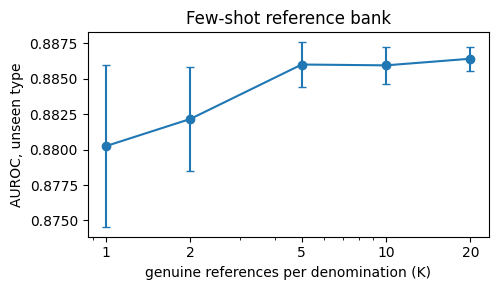

In [ ]:
rng = np.random.default_rng(CFG['SEED']); KS = [1, 2, 5, 10, 20]; FEW = {}
for K in KS:
    aucs = []
    for _ in range(10):
        bE, bD = build_bank(model, SPLIT['train'], K, rng); s = score(TE, TD, bE, bD)
        aucs.append(roc_auc_score(TY[held_m], s[held_m]))
    FEW[K] = (float(np.mean(aucs)), float(np.std(aucs)))
    print(f'K = {K:2d} genuine references per denomination -> unseen-type AUROC {FEW[K][0]:.3f} +/- {FEW[K][1]:.3f}')
print(f"K = all ({len(SPLIT['train'])} notes)                 -> unseen-type AUROC {RES['unseen']['auroc']:.3f}")

vH = eval_items(SPLIT['val'], [CFG['HOLDOUT']], shots=2)
vE2, vY2, vD2 = embed_items(model, vH); vs2 = score(vE2, vD2, BE, BD)
gen_v, fake_v = vs2[vY2 == 0], vs2[vY2 == 1]
def best_thr(g, f):
    y = np.r_[np.zeros(len(g)), np.ones(len(f))]; s = np.r_[g, f]
    fpr, tpr, th = roc_curve(y, s); return th[np.argmax(tpr - fpr)]
CAL = {}
for n in (0, 5, 10):
    rec, fprs = [], []
    for _ in range(30 if n else 1):
        thr = RES['threshold'] if n == 0 else best_thr(gen_v, rng.choice(fake_v, min(n, len(fake_v)), replace=False))
        p = TS >= thr
        rec.append(p[(KINDS_TEST == CFG['HOLDOUT'])].mean()); fprs.append(p[KINDS_TEST == 'genuine'].mean())
    CAL[n] = dict(recall_unseen=float(np.mean(rec)), fpr_genuine=float(np.mean(fprs)))
    print(f"{'seen-type threshold' if n == 0 else f'calibrated with {n} unseen examples':36} recall on unseen type {CAL[n]['recall_unseen']:.3f}   false alarms on genuine {CAL[n]['fpr_genuine']:.3f}")

plt.figure(figsize=(5, 3)); m_ = [FEW[k][0] for k in KS]; sd = [FEW[k][1] for k in KS]
plt.errorbar(KS, m_, sd, marker='o', capsize=3); plt.xscale('log'); plt.xticks(KS, KS)
plt.xlabel('genuine references per denomination (K)'); plt.ylabel('AUROC, unseen type'); plt.title('Few-shot reference bank')
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/few_shot.png", dpi=120); plt.show()

## 13. Explainability: where is the defect?
**Grad-CAM on the verification distance**: the gradient of the note's distance to its nearest genuine reference
with respect to the last convolutional feature map. It is compared with **PatchCore's** patch-anomaly map.
The **pointing-game** score is the fraction of counterfeits whose hottest heatmap pixel falls inside the true defect
region (chance level = the defect's area share).

/tmp/ipykernel_469/3211917632.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return cam / (cam.max() + 1e-8), float(dist)


Pointing game: share of counterfeits whose hottest pixel is inside the true defect
type                  Grad-CAM  PatchCore   chance
blur                      0.58       0.13     0.15
microtext_blur            0.47       0.10     0.16
ink_drift                 0.63       0.17     0.16
misregistration           0.87       0.38     0.42
color_shift               0.65       0.12     0.15
halftone                  0.95       0.80     0.16
hologram_failure          0.48       0.22     0.15
texture_damage            0.83       0.00     0.15
missing_ink               0.48       0.00     0.15
mean                      0.66       0.21     0.18


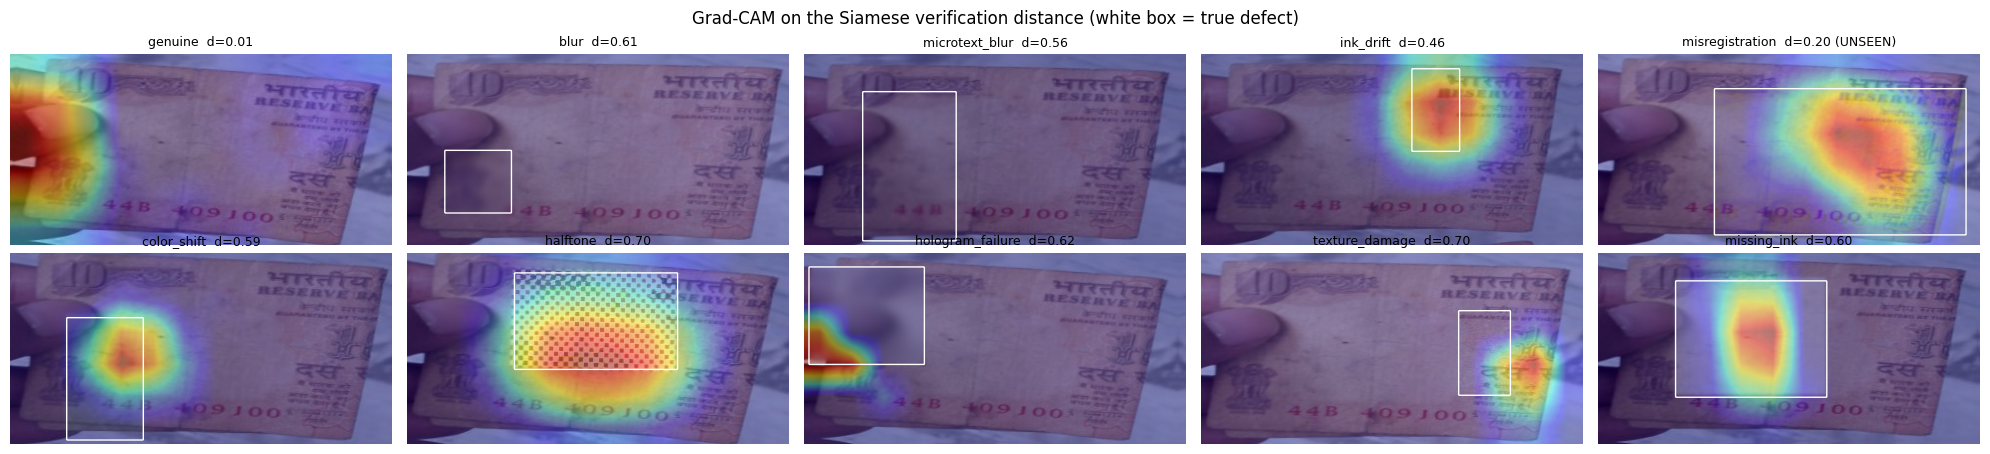

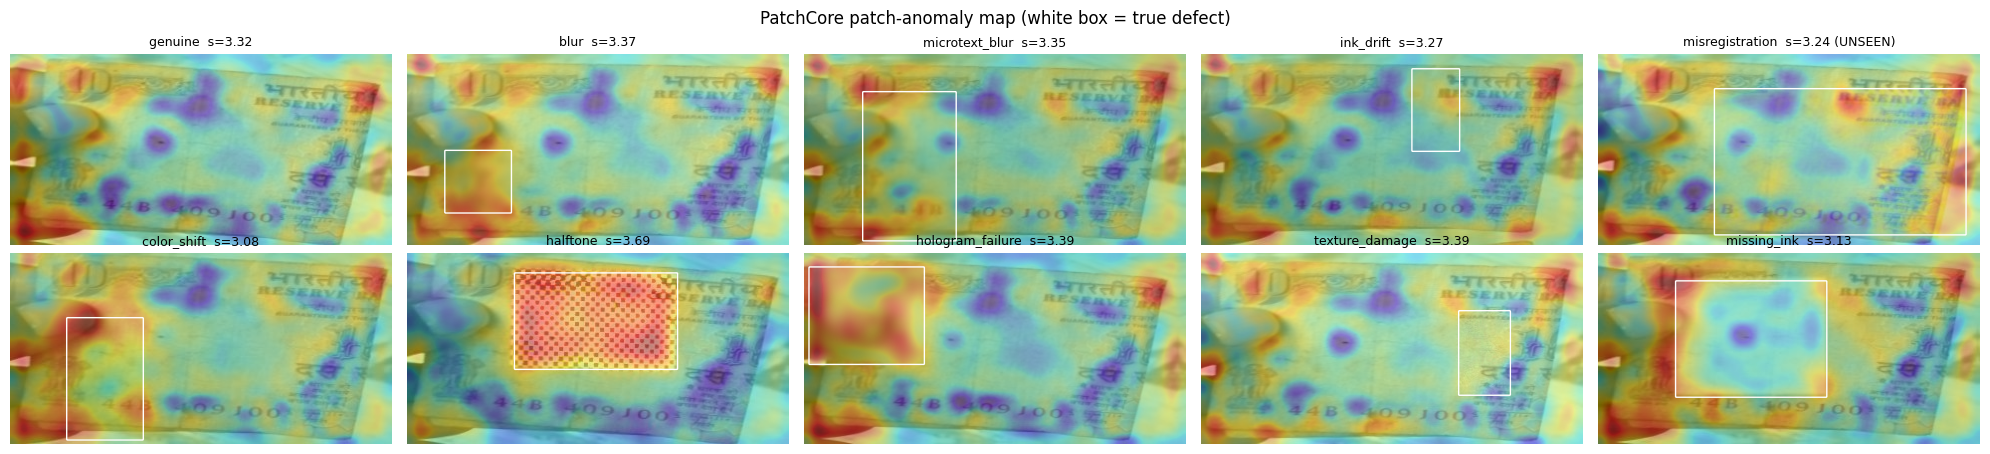

In [ ]:
def gradcam(model, img_u8, denom):
    model.eval(); x = to_tensor(img_u8)[None].to(DEVICE)
    fmap = model.body(x); fmap.retain_grad()
    e = model.embed_from_fmap(fmap)
    ref = torch.from_numpy(BE[BD == denom] if (BD == denom).any() else BE).to(DEVICE)
    dist = torch.cdist(e.float(), ref.float()).min()
    model.zero_grad(); dist.backward()
    w = fmap.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * fmap).sum(1))[0].detach().float().cpu().numpy()
    cam = cv2.resize(cam, (img_u8.shape[1], img_u8.shape[0]))
    return cam / (cam.max() + 1e-8), float(dist)

ITEM_POS = {it: k for k, it in enumerate(TEST_ITEMS)}          # (note, kind, shot) -> index in PatchCore maps
hits = {m: {t: [] for t in TYPES} for m in ('gradcam', 'patchcore')}; chance = {t: [] for t in TYPES}
for i in SPLIT['test'][:60]:
    for t in TYPES:
        img, mk = make_sample(NOTES[i]['img'], t, det_rng(i, t, 0))
        cam, _ = gradcam(model, img, NOTES[i]['denom'])
        pc = patchcore_heatmap(PC_MAPS[ITEM_POS[(i, t, 0)]], *mk.shape)
        for m, h in (('gradcam', cam), ('patchcore', pc)):
            y, x = np.unravel_index(h.argmax(), h.shape); hits[m][t].append(mk[y, x] > 0.5)
        chance[t].append(mk.mean())
LOC = {t: dict(gradcam=float(np.mean(hits['gradcam'][t])), patchcore=float(np.mean(hits['patchcore'][t])),
               chance=float(np.mean(chance[t]))) for t in TYPES}
print('Pointing game: share of counterfeits whose hottest pixel is inside the true defect')
print(f"{'type':20}{'Grad-CAM':>10}{'PatchCore':>11}{'chance':>9}")
for t in TYPES: print(f"{t:20}{LOC[t]['gradcam']:10.2f}{LOC[t]['patchcore']:11.2f}{LOC[t]['chance']:9.2f}")
print(f"{'mean':20}{np.mean([v['gradcam'] for v in LOC.values()]):10.2f}{np.mean([v['patchcore'] for v in LOC.values()]):11.2f}{np.mean([v['chance'] for v in LOC.values()]):9.2f}")

i = SPLIT['test'][0]
for method in ('gradcam', 'patchcore'):
    fig, ax = plt.subplots(2, 5, figsize=(20, 4.6))
    for a, k in zip(ax.ravel(), ['genuine'] + TYPES):
        img, mk = make_sample(NOTES[i]['img'], k, det_rng(i, k, 0))
        if method == 'gradcam':
            h, dist = gradcam(model, img, NOTES[i]['denom']); lab = f'd={dist:.2f}'
        else:
            pos = ITEM_POS[(i, k, 0)]; h = patchcore_heatmap(PC_MAPS[pos], *mk.shape); lab = f's={PC_S[pos]:.2f}'
            h = h / (h.max() + 1e-8)
        a.imshow(img); a.imshow(h, cmap='jet', alpha=0.4)
        if mk.any(): a.contour(mk, levels=[0.5], colors='w', linewidths=1)
        a.set_title(f'{k}  {lab}' + (' (UNSEEN)' if k == CFG['HOLDOUT'] else ''), fontsize=9); a.axis('off')
    plt.suptitle(('Grad-CAM on the Siamese verification distance' if method == 'gradcam' else 'PatchCore patch-anomaly map')
                 + ' (white box = true defect)'); plt.tight_layout()
    plt.savefig(f"{CFG['OUT']}/{method}_heatmaps.png", dpi=120); plt.show()

## 14. (Optional) Full leave-one-type-out over every counterfeit type
Holds out each of the 9 counterfeit types in turn and trains the **Siamese model, the supervised CNN and XGBoost**
for each, so the unseen-type comparison is averaged over all types instead of resting on one. About 2.5–3 hours.
Progress is saved to Google Drive after every type; if Colab disconnects, re-run sections 1–11 (skip 11b–13)
and then this cell again, and it continues where it stopped. Set `RUN_ALL = True` to run.

In [ ]:
RUN_ALL = False
if RUN_ALL:
    from google.colab import drive; drive.mount('/content/drive')
    LOTO_PATH = '/content/drive/MyDrive/counterfeit_loto.json'
    LOTO = json.load(open(LOTO_PATH)) if os.path.exists(LOTO_PATH) else {}
    for h in TYPES:
        if h in LOTO:
            print(f'{h:18} already done'); continue
        t0 = time.time()
        seen_h = [t for t in TYPES if t != h]
        sm, hm = masks_for(KINDS_TEST, seen_h), masks_for(KINDS_TEST, [h])
        m_h, _ = train_siamese(h, epochs=8, tag=f'loto_{h}', verbose=False)
        r, (tE_h, tY_h, _, _, _, _) = evaluate_siamese(m_h, h)
        trE_h, trY_h, _ = embed_items(m_h, eval_items(SPLIT['train'], seen_h, shots=1))
        px = make_pipeline(StandardScaler(), XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                           eval_metric='logloss')).fit(trE_h, trY_h).predict_proba(tE_h)[:, 1]
        del m_h; torch.cuda.empty_cache()
        c_h = train_cnn_classifier(h, epochs=5); pc = cnn_scores(c_h, TEST_ITEMS)
        del c_h; torch.cuda.empty_cache()
        LOTO[h] = {'siamese': {'seen': r['seen']['auroc'], 'unseen': r['unseen']['auroc']},
                   'cnn':     {'seen': float(roc_auc_score(TY[sm], pc[sm])), 'unseen': float(roc_auc_score(TY[hm], pc[hm]))},
                   'xgboost': {'seen': float(roc_auc_score(tY_h[sm], px[sm])), 'unseen': float(roc_auc_score(tY_h[hm], px[hm]))}}
        json.dump(LOTO, open(LOTO_PATH, 'w'), indent=2)
        print(f"{h:18} unseen AUROC  Siamese {LOTO[h]['siamese']['unseen']:.3f} | CNN {LOTO[h]['cnn']['unseen']:.3f} | "
              f"XGBoost {LOTO[h]['xgboost']['unseen']:.3f}   ({(time.time() - t0) / 60:.0f} min)")
    print(f"\n{'held-out type':18}{'Siamese':>9}{'CNN':>8}{'XGBoost':>9}")
    for h, v in LOTO.items(): print(f"{h:18}{v['siamese']['unseen']:9.3f}{v['cnn']['unseen']:8.3f}{v['xgboost']['unseen']:9.3f}")
    print(f"{'MEAN':18}" + ''.join(f"{np.mean([v[m]['unseen'] for v in LOTO.values()]):{w}.3f}" for m, w in (('siamese', 9), ('cnn', 8), ('xgboost', 9))))
    json.dump(LOTO, open(f"{CFG['OUT']}/leave_one_type_out_all.json", 'w'), indent=2)

## 15. (Optional) Test on REAL counterfeit photos
Set `KAGGLE_REAL_FAKE` in section 2 to a real-vs-fake Indian currency dataset (folders named real/fake per
denomination) and run this cell. These photos are **never** used in training; their genuine notes become extra test
genuines and their fakes are scored against the same reference bank. Expect lower scores: different cameras,
backgrounds and forgery methods are a domain shift. Check that the "fake" images really are counterfeits
(not just photos of the same notes) before reporting this.

In [ ]:
REAL = None
if CFG['KAGGLE_REAL_FAKE']:
    src = kaggle_download(CFG['KAGGLE_REAL_FAKE'])
    rnotes = build_note_table(scan_notes(src), CFG['IMG_H'], CFG['IMG_W'], 0, CFG['CROP_NOTES'], CFG['DET_MIN_SCORE'])
    labs = np.array([n['label'] == 'fake' for n in rnotes]).astype(int)
    print('real-vs-fake set:', int((labs == 0).sum()), 'genuine,', int(labs.sum()), 'fake')
    if labs.min() != labs.max():
        model.eval(); E = []
        with torch.no_grad():
            for b in range(0, len(rnotes), 64):
                x = torch.stack([to_tensor(n['img']) for n in rnotes[b:b + 64]]).to(DEVICE)
                E.append(model(x).float().cpu())
        E = torch.cat(E).numpy(); D = np.array([n['denom'] for n in rnotes])
        s = score(E, D, BE, BD); REAL = dict(auroc=float(roc_auc_score(labs, s)), n=len(labs))
        print(f"AUROC on real counterfeit photos: {REAL['auroc']:.3f}")
    else:
        print('Could not find both real and fake folders; check the layout printed above.')

## 16. UCI Banknote Authentication (tabular benchmark)
1,372 notes described by 4 wavelet features (variance, skewness, curtosis, entropy), not images, so the CNN cannot use it.
It compares, on a public benchmark, **supervised classifiers** (trained on genuine and forged notes) with a
**verifier fitted on genuine notes only** (our framing: distance from the genuine distribution). 5-fold CV.

In [ ]:
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors

def uci_benchmark(X, y, folds=5, seed=CFG['SEED']):
    res = {}
    for tr, te in StratifiedKFold(folds, shuffle=True, random_state=seed).split(X, y):
        for name, p in classical_baselines(X[tr], y[tr], X[te]).items():
            res.setdefault(f'classifier: {name}', []).append(roc_auc_score(y[te], p))
        g = X[tr][y[tr] == 0]; sc = StandardScaler().fit(g); G, T = sc.transform(g), sc.transform(X[te])
        d = T - G.mean(0); ci = np.linalg.pinv(np.cov(G, rowvar=False))
        res.setdefault('verifier (genuine only): Mahalanobis', []).append(roc_auc_score(y[te], np.sqrt(np.einsum('ij,jk,ik->i', d, ci, d))))
        res.setdefault('verifier (genuine only): 5-NN distance', []).append(
            roc_auc_score(y[te], NearestNeighbors(n_neighbors=5).fit(G).kneighbors(T)[0].mean(1)))
    return {k: (float(np.mean(v)), float(np.std(v))) for k, v in res.items()}

uci = fetch_ucirepo(id=267)
Xu = uci.data.features.to_numpy(np.float64); yu = uci.data.targets.to_numpy().ravel().astype(int)
print(f'UCI: {len(yu)} notes ({(yu == 0).sum()} genuine, {(yu == 1).sum()} forged)\n')
UCI = uci_benchmark(Xu, yu)
for k, (m, s) in UCI.items(): print(f'{k:44} AUROC {m:.4f} +/- {s:.4f}')

UCI: 1372 notes (762 genuine, 610 forged)

classifier: SVM (RBF)                        AUROC 1.0000 +/- 0.0000
classifier: Random Forest                    AUROC 0.9999 +/- 0.0001
classifier: Logistic Regression              AUROC 0.9996 +/- 0.0003
classifier: MLP                              AUROC 1.0000 +/- 0.0000
classifier: XGBoost                          AUROC 1.0000 +/- 0.0001
verifier (genuine only): Mahalanobis         AUROC 0.9988 +/- 0.0010
verifier (genuine only): 5-NN distance       AUROC 0.9977 +/- 0.0025


## 17. Save everything and download
Saves all numbers to `summary.json`, the figures, and the trained weights, then downloads one zip.
Copy the tables into your slides from `summary.json`.

In [ ]:
summary = dict(config=CFG, n_notes={k: len(v) for k, v in SPLIT.items()}, denominations=DENOMS,
               siamese=RES, baselines={k: {'seen': float(a), 'unseen': float(b)} for k, (a, b) in BASE.items()},
               patchcore_per_type_auroc=PC_PER_TYPE, few_shot_reference=FEW, few_shot_calibration=CAL, localisation=LOC, real_counterfeits=REAL,
               uci={k: {'auroc_mean': m, 'auroc_std': s} for k, (m, s) in UCI.items()}, history=HIST)
json.dump(summary, open(f"{CFG['OUT']}/summary.json", 'w'), indent=2, default=str)
torch.save(model.state_dict(), f"{CFG['OUT']}/siamese_final.pt")
import shutil; shutil.make_archive('/content/counterfeit_results', 'zip', CFG['OUT'])
print(open(f"{CFG['OUT']}/summary.json").read()[:1500], '...')
from google.colab import files; files.download('/content/counterfeit_results.zip')

{
  "config": {
    "KAGGLE_GENUINE": "vishalmane109/indian-currency-note-images-dataset-2020",
    "KAGGLE_REAL_FAKE": "",
    "MAX_PER_DENOM": 200,
    "CROP_NOTES": true,
    "DET_MIN_SCORE": 0.2,
    "MIN_PER_DENOM": 20,
    "IMG_H": 192,
    "IMG_W": 384,
    "SPLIT": [
      0.6,
      0.2,
      0.2
    ],
    "HOLDOUT": "misregistration",
    "BACKBONE": "resnet18",
    "POOL": "topk",
    "EMB_DIM": 128,
    "LOSS": "triplet",
    "MARGIN": 0.3,
    "EPOCHS": 20,
    "BATCH": 32,
    "LR": 0.0003,
    "PATIENCE": 5,
    "STEPS_PER_EPOCH": 0,
    "CNN_BASELINE_EPOCHS": 10,
    "SEED": 42,
    "OUT": "/content/results"
  },
  "n_notes": {
    "train": 827,
    "val": 282,
    "test": 291
  },
  "denominations": [
    10,
    20,
    50,
    100,
    200,
    500,
    2000
  ],
  "siamese": {
    "threshold": 0.2406303882598877,
    "seen": {
      "auroc": 0.9516545919391599,
      "eer": 0.11469072164948454,
      "tpr_at_1pct_fpr": 0.6911512027491409,
      "precision": 0.9744

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/counterfeit_cache', exist_ok=True)
np.savez_compressed('/content/drive/MyDrive/counterfeit_cache/notes_cropped.npz',
    imgs=np.stack([n['img'] for n in NOTES]), denoms=np.array([n['denom'] for n in NOTES]),
    groups=np.array([n['group'] for n in NOTES]),
    cfg=json.dumps({k: CFG[k] for k in ('KAGGLE_GENUINE', 'MAX_PER_DENOM', 'MIN_PER_DENOM', 'IMG_H', 'IMG_W',
                                         'CROP_NOTES', 'DET_MIN_SCORE', 'SEED')}))
print('saved', len(NOTES), 'notes')

Mounted at /content/drive
saved 1400 notes
